<h1>EN 3160 - Assignment 2</h1>
<h2>Fitting and Alignment</h2>
<h3>Index No. - 230013A</h3>
<h3>Name - D. H. Abeywarna</h3>
Github - <a href="https://github.com/dilith813/en3160-a02">https://github.com/dilith813/en3160-a02</a>

# Question 1: Blob detection with the Laplacian of Gaussian

In [1]:
import cv2 as cv
import numpy as np
import matplotlib.pyplot as plt
from scipy.ndimage import maximum_filter

# Loading the image
im = cv.imread('../images/the_berry_farms_sunflower_field.jpeg', cv.IMREAD_REDUCED_COLOR_4)
assert im is not None, "image not found: check the path in images/"
rgb = cv.cvtColor(im, cv.COLOR_BGR2RGB)

# Single channel versions to detect blobs on
b, g, r = [c.astype(np.float32) / 255 for c in cv.split(im)]
gray_ch = cv.cvtColor(im, cv.COLOR_BGR2GRAY).astype(np.float32) / 255
yellow_ch = np.clip((r + g) / 2 - b, 0, None)     # high on yellow petals, zero on sky and clouds
print(im.shape)

(360, 360, 3)


In [2]:
# Scale-space blob detector using scale-normalized Laplacian of Gaussian
def detect_blobs(img, sigmas, thr_rel=0.3, color_mask=None, min_color=0.15):
    space = np.empty((len(sigmas),) + img.shape, np.float32)
    for i, s in enumerate(sigmas):
        blurred = cv.GaussianBlur(img, (0, 0), s)
        space[i] = -(s ** 2) * cv.Laplacian(blurred, cv.CV_32F)

    # Scale-space extrema
    is_max = space == maximum_filter(space, size=(3, 3, 3))
    pts = np.argwhere(is_max & (space > thr_rel * space.max()))
    cands = sorted([(space[l, y, x], x, y, sigmas[l]) for l, y, x in pts], reverse=True)

    keep = []
    for resp, x, y, s in cands:
        if color_mask is not None and color_mask[y, x] <= min_color:
            continue
        if all(np.hypot(x - xk, y - yk) > max(np.sqrt(2) * s, np.sqrt(2) * sk) for _, xk, yk, sk in keep):
            keep.append((resp, x, y, s))
    return keep

In [8]:
# Draw circles (radius = sqrt(2) * sigma)
def show(circles, title, n=5):
    out = rgb.copy()
    for _, x, y, s in circles:
        cv.circle(out, (int(x), int(y)), int(round(np.sqrt(2) * s)), (255, 0, 0), 2)
    plt.figure(figsize=(9, 7)); plt.imshow(out)
    plt.xticks(range(0, out.shape[1], 50)); plt.yticks(range(0, out.shape[0], 50))
    plt.grid(alpha=0.3); plt.xlabel('x (pixels)'); plt.ylabel('y (pixels)')
    plt.title(f"{title}: {len(circles)} circles"); plt.show()
    print(f"{'x':>5} {'y':>5} {'sigma':>7} {'radius':>7}")
    for _, x, y, s in sorted(circles, key=lambda c: c[3], reverse=True)[:n]:
        print(f"{x:5d} {y:5d} {s:7.2f} {np.sqrt(2) * s:7.1f}")

**Method:** A blob is a region that stands out from its surroundings at some size.The Laplacian of Gaussian (LoG) responds strongly where the image, smoothed with a Gaussian of width sigma ($\sigma$) has a bright spot of about that size. To find blobs of every size, the image is processed at a range of $\sigma$ values (the scale space). The response is multiplied by sigma squared, otherwise larger sigmas would always give weaker responses and big blobs would never win. A blob is detected where the response is a maximum in position and in scale, and above a threshold. Here, maximum means it has to be larger than all 26 neighbors in the 3x3x3 neighborhood. For a circular blob of radius r, the response peaks at $\sigma$ = r / sqrt(2), so each detection is drawn as a circle of radius sqrt(2) times $\sigma$. Circles whose center lies inside a stronger circle are removed, so each flower gets only circle.

**Sigma Range:** Sigma values follow a geometric series, (3x1.2)^k. Since a blob of any size should be equally easy to detect, scales are spaced by a constant ratio. The smallest $\sigma$, 3, corresponds to a radius of 4.2 pixels. The largest $\sigma$ sets the largest detectable blob and is limited by the flower size. The first run (grayscale) used 18 levels, sigma 3 to 66.6. The final run used
14 levels, sigma 3 to 32.1 (radius 4.2 to 45.4 pixels). The ratio 1.2 and the number of levels were
chosen by judgement and not tuned.
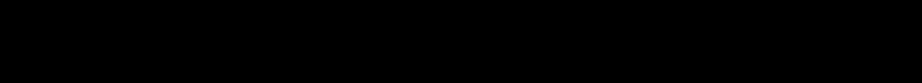
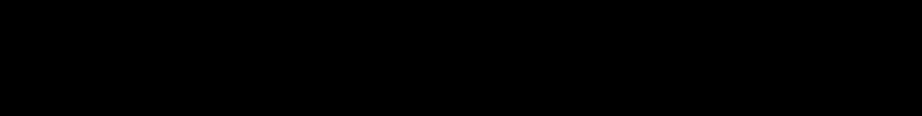
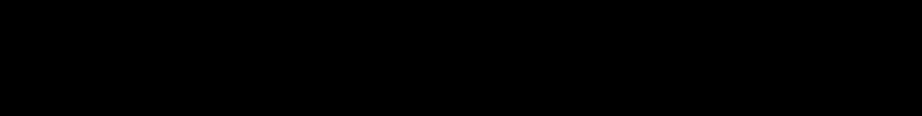
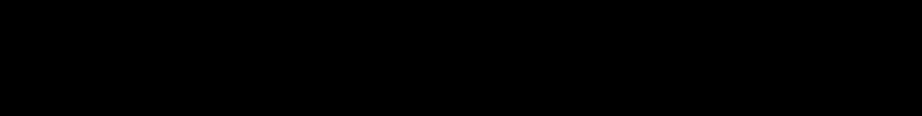
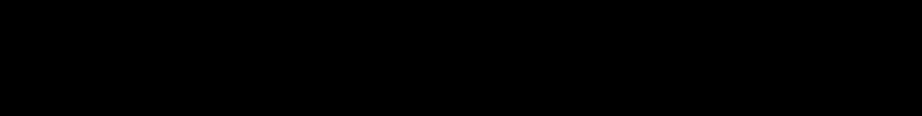

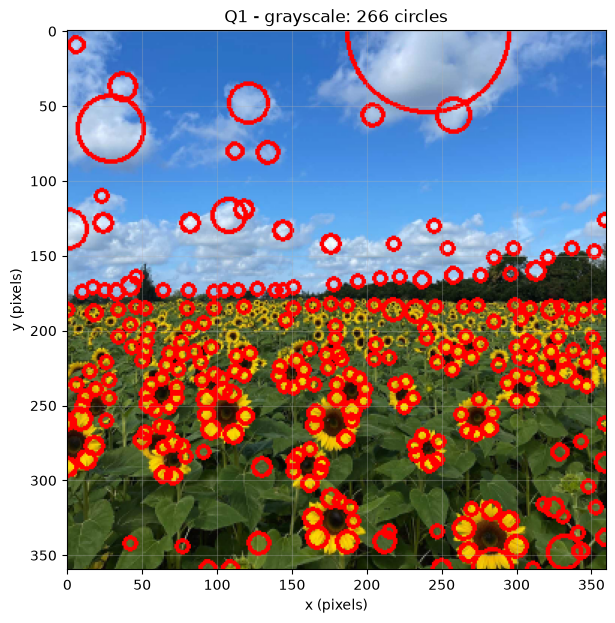

    x     y   sigma  radius
  241     0   38.52    54.5
   29    65   15.48    21.9
  284   359    8.96    12.7
  121    48    8.96    12.7
    0   132    8.96    12.7
sigma range: 3.00 to 66.56


In [9]:
# Q1 - run 1: grayscale
sig_gray = 3.0 * 1.2 ** np.arange(18)
circ_gray = detect_blobs(gray_ch, sig_gray)
show(circ_gray, "Q1 - grayscale")
print(f"sigma range: {sig_gray[0]:.2f} to {sig_gray[-1]:.2f}")

**First Attempt (Grayscale):** Four of the five largest circles were on clouds in the sky. The largest had sigma
38.52 and radius 54.5 at (241, 0), a cloud cut by the top border. Brightness alone cannot separate white clouds from yellow petals, because both are bright blobs.

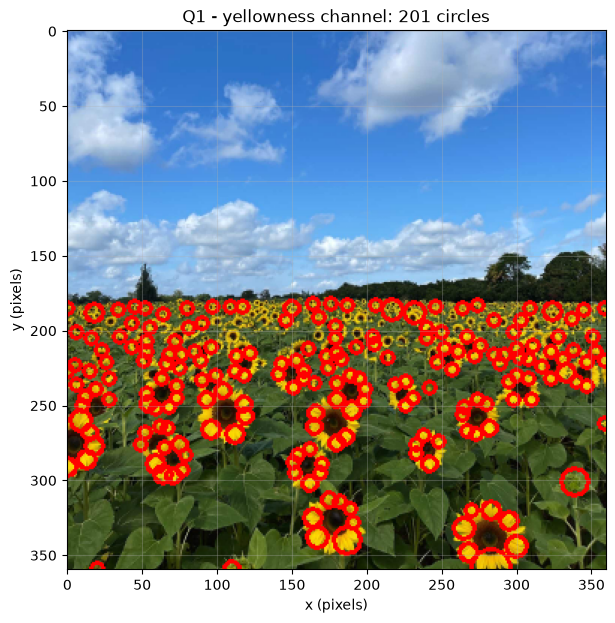

    x     y   sigma  radius
  283   359    8.96    12.7
  187   340    6.22     8.8
  339   301    6.22     8.8
  167   338    5.18     7.3
  300   344    5.18     7.3
sigma range: 3.00 to 66.56  (radius 4.2 to 94.1 px)


In [10]:
# Q1 - run 2: yellowness channel
sig = 3.0 * 1.2 ** np.arange(18)
yellow_smooth = cv.GaussianBlur(yellow_ch, (0, 0), 2)
circ_yel = detect_blobs(yellow_ch, sig, thr_rel=0.3, color_mask=yellow_smooth, min_color=0.15)
show(circ_yel, "Q1 - yellowness channel")
print(f"sigma range: {sig[0]:.2f} to {sig[-1]:.2f}  (radius {np.sqrt(2)*sig[0]:.1f} to {np.sqrt(2)*sig[-1]:.1f} px)")

**Final Detector (Yellowness Channel):** Detection was run on (R + G) / 2 - B, clipped at zero. This is high for yellow petals and zero for white clouds and the sky. The result is 201 circles, all on the sunflower field.
Re-running with 18 levels (sigma up to 66.6) also gave no sky detections. The largest detected sigma
was only 8.96, far below the upper limit, so the upper limit did not matter on this channel.

**Largest Circles (Final run):**
| x | y | sigma | radius (px) |
|---|---|---|---|
| 283 | 359 | 8.96 | 12.7 |
| 187 | 340 | 6.22 | 8.8 |
| 339 | 301 | 6.22 | 8.8 |
| 167 | 338 | 5.18 | 7.3 |
| 300 | 344 | 5.18 | 7.3 |


**Discussion and Limitations:**
- The circles mostly sit on single petals or small groups of petals, not on whole flower heads. The
  largest circle has radius 12.7 px, while the largest flower heads are about 50 px across (radius
  about 25 px). In this channel a flower head is a bright ring of petals around a dark centre, which
  gives a weaker response at the scale of the whole head than a single petal does at a smaller scale.
- Some visible petals have no circle. A detection needs a local maximum above a threshold set by the
  strongest response, so paler or shaded petals fall below it, and circles inside a stronger circle
  are removed. (However, it should be mentioned that some green parts of the flowers have been marked by a circle, despite being visually less intense than yellow petals).
- Circles cut by the image border describe only part of a blob.


# Question 2: RANSAC Line and Circle Fitting

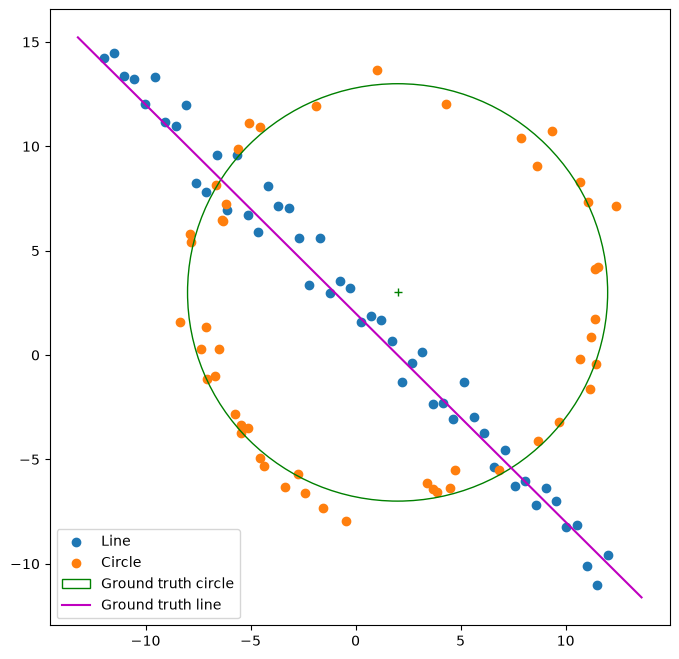

In [13]:
# Q2 - Listing 1: Generating a noisy point set conforming to a line and a circle
import numpy as np
from scipy.optimize import minimize
from scipy import linalg
import matplotlib.pyplot as plt

np.random.seed(0)                       # fixed so the report numbers can be reproduced
N = 100
half_n = N // 2
r = 10
x0_gt, y0_gt = 2, 3
s = r / 16
t = np.random.uniform(0, 2 * np.pi, half_n)
n = s * np.random.randn(half_n)
x, y = x0_gt + (r + n) * np.cos(t), y0_gt + (r + n) * np.sin(t)
X_circ = np.hstack((x.reshape(half_n, 1), y.reshape(half_n, 1)))

s = 1.
m, b = -1, 2
x = np.linspace(-12, 12, half_n)
y = m * x + b + s * np.random.randn(half_n)
X_line = np.hstack((x.reshape(half_n, 1), y.reshape(half_n, 1)))
X = np.vstack((X_circ, X_line))

fig, ax = plt.subplots(1, 1, figsize=(8, 8))
ax.scatter(X_line[:, 0], X_line[:, 1], label='Line')
ax.scatter(X_circ[:, 0], X_circ[:, 1], label='Circle')
circle_gt = plt.Circle((x0_gt, y0_gt), r, color='g', fill=False, label='Ground truth circle')
ax.add_patch(circle_gt)
ax.plot((x0_gt), (y0_gt), '+', color='g')
x_min, x_max = ax.get_xlim()
x_ = np.array([x_min, x_max])
y_ = m * x_ + b
plt.plot(x_, y_, color='m', label='Ground truth line')
plt.legend()
plt.show()

The data are 50 points on a circle (centre (2, 3), radius 10, radial noise with standard deviation
0.625) and 50 points on the line y = -x + 2 (vertical noise with standard deviation 1). Each
structure is the outlier set for the other, so ordinary least squares would fail on the mixed data.
RANSAC avoids this: it repeatedly fits a model to a minimal random sample (2 points for a line, 3
for a circle), counts how many points agree with it (the consensus set), and keeps the model with the
largest consensus set. The final model is then refitted on its consensus set only.

In [14]:
# Q2(a) - RANSAC for the line
rng = np.random.default_rng(1)

def line_from_two_points(p, q):
    d = q - p
    nrm = np.array([-d[1], d[0]]) / np.linalg.norm(d)    # unit normal, so ||[a,b]|| = 1 by construction
    return nrm[0], nrm[1], nrm @ p                       # line is a*x + b*y = d

def line_errors(P, a, b, d):
    return np.abs(P @ np.array([a, b]) - d)              # normal (perpendicular) distance to the line

def ransac_line(P, thresh=1.5, min_inliers=35, iters=300, rng=rng):
    best = dict(count=0)
    for _ in range(iters):
        i, j = rng.choice(len(P), 2, replace=False)      # minimal sample: 2 points define a line
        a, b, d = line_from_two_points(P[i], P[j])
        inl = line_errors(P, a, b, d) < thresh
        if inl.sum() > best['count']:
            best = dict(count=inl.sum(), inl=inl, sample=P[[i, j]], model=(a, b, d))
    assert best['count'] >= min_inliers, "consensus too small"
    # Q2(a) - Refit on all inliers by total least squares
    Q = P[best['inl']]; mu = Q.mean(0)
    nrm = np.linalg.svd(Q - mu)[2][-1]
    best['refit'] = (nrm[0], nrm[1], nrm @ mu)
    return best

line = ransac_line(X)
print("line inliers:", line['count'], " (a, b, d) =", np.round(line['refit'], 3))
print("ground truth (a, b, d):", np.round(np.array([1, 1, 2]) / np.sqrt(2) * np.array([1, 1, 1]), 3))

line inliers: 55  (a, b, d) = [0.717 0.697 1.503]
ground truth (a, b, d): [0.707 0.707 1.414]


### Q2(a): Line RANSAC
The line is written as a x + b y = d, where (a, b) is the unit normal and d is the distance from the
origin. For two sampled points the normal is the direction between them rotated by 90 degrees and
divided by its length, so the constraint that (a, b) has length 1 holds by construction. The error of a
point is its normal distance to the line, |a x + b y - d|.

**Settings:**
- Error threshold was chosen as 1.5. The line noise has standard deviation 1, so 1.5 keeps most true line
points (about 87 percent) while excluding most circle points.

- Minimum consensus was 35. The line has 50
points, so a good line must contain a clear majority of them.

- 300 iterations: a random pair is entirely
from the line with probability about 0.25, so about 16 draws already give 99 percent confidence of at
least one good sample, and 300 is generous.

**Refit:** The best sample only gives a rough line. It is refitted on all its inliers with total
least squares. The normal is the singular vector of the centred inlier points with the smallest
singular value, which again has unit length. The result was a line with 55 inliers and
(a, b, d) = (0.717, 0.697, 1.503), against the ground truth (0.707, 0.707, 1.414) up to overall sign.

In [15]:
# Q2(b) - Remove the line's consensus set, then RANSAC for the circle
def circle_from_three(p1, p2, p3):
    A = 2 * np.array([p2 - p1, p3 - p1])
    if abs(np.linalg.det(A)) < 1e-6:                     # nearly collinear: no usable circle
        return None
    rhs = np.array([p2 @ p2 - p1 @ p1, p3 @ p3 - p1 @ p1])
    c = np.linalg.solve(A, rhs)                          # center is equidistant from the three points
    return c, np.linalg.norm(p1 - c)

def circle_errors(P, c, r):
    return np.abs(np.linalg.norm(P - c, axis=1) - r)     # radial error

def fit_circle(Q, c0, r0):
    # Q2(b) - Refit of center and radius with least-squares (scipy.optimize.minimize)
    cost = lambda p: np.sum((np.linalg.norm(Q - p[:2], axis=1) - p[2]) ** 2)
    res = minimize(cost, [c0[0], c0[1], r0])
    return res.x[:2], res.x[2]

def ransac_circle(P, thresh=1.5, min_inliers=30, iters=500, rng=rng):
    best = dict(count=0)
    for _ in range(iters):
        idx = rng.choice(len(P), 3, replace=False)       # minimal sample: 3 points define a circle
        out = circle_from_three(*P[idx])
        if out is None:
            continue
        c, r_ = out
        inl = circle_errors(P, c, r_) < thresh
        if inl.sum() > best['count']:
            best = dict(count=inl.sum(), inl=inl, sample=P[idx], model=(c, r_))
    assert best['count'] >= min_inliers, "consensus too small"
    best['refit'] = fit_circle(P[best['inl']], *best['model'])
    return best

remnant = X[~line['inl']]
print("points left after removing the line:", len(remnant))
circ = ransac_circle(remnant)
c_fit, r_fit = circ['refit']
print("circle inliers:", circ['count'], " centre", np.round(c_fit, 2), " radius", round(r_fit, 2))
print("ground truth: centre (2, 3), radius 10")

points left after removing the line: 45
circle inliers: 45  centre [1.86 3.07]  radius 9.95
ground truth: centre (2, 3), radius 10


### Q2(b): Circle
The line's consensus set is removed, leaving ___ points. A circle is fitted to three random points
by finding the point equidistant from them (a 2x2 linear system), and the error of a point is its
radial error, | distance to center - radius |. Samples with nearly collinear points are skipped.

**Settings.**
- Error threshold 1.5: The radial noise has standard deviation 0.625, so 1.5 is about 2.4
standard deviations and keeps almost all true circle points.
- Minimum consensus 30: About 50 circle
points remain minus a few that were removed with the line, so a correct circle should have at least 30.
- Iterations 500.

**Refit.** The center and radius are refined on the inliers by minimizing the sum of squared radial
errors with scipy.optimize.minimize, starting from the sample's circle. Result: 45 inliers, center (1.86, 3.07),
radius 9.95, against the ground truth center (2, 3) and radius 10.

The line and circle cross, so the few circle points near the crossing were counted as line inliers and
removed from the circle's data. This is an unavoidable overlap.

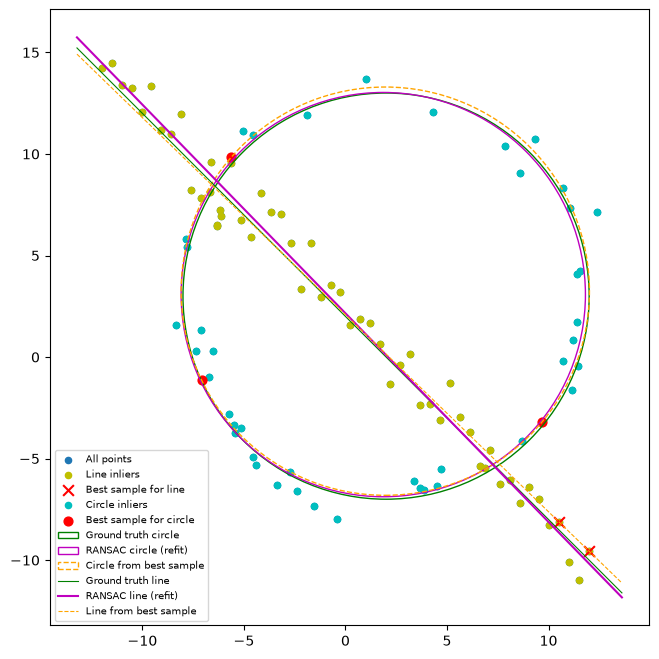

In [16]:
# Q2(c) - Plotting
fig, ax = plt.subplots(figsize=(8, 8))
ax.scatter(*X.T, s=20, label='All points')
ax.scatter(*X[line['inl']].T, c='y', s=20, label='Line inliers')
ax.scatter(*line['sample'].T, c='r', marker='x', s=60, label='Best sample for line')
ax.scatter(*remnant[circ['inl']].T, c='c', s=20, label='Circle inliers')
ax.scatter(*circ['sample'].T, c='r', s=40, label='Best sample for circle')

ax.add_patch(plt.Circle((x0_gt, y0_gt), r, color='g', fill=False, label='Ground truth circle'))
ax.add_patch(plt.Circle(c_fit, r_fit, color='m', fill=False, label='RANSAC circle (refit)'))
cs, rs = circ['model']
ax.add_patch(plt.Circle(cs, rs, color='orange', fill=False, ls='--', label='Circle from best sample'))

xs = np.array(ax.get_xlim())
ax.plot(xs, m * xs + b, c='g', lw=0.8, label='Ground truth line')
a_, b_, d_ = line['refit']
ax.plot(xs, (d_ - a_ * xs) / b_, c='m', label='RANSAC line (refit)')
a_, b_, d_ = line['model']
ax.plot(xs, (d_ - a_ * xs) / b_, c='orange', ls='--', lw=0.8, label='Line from best sample')
ax.set_aspect('equal'); ax.legend(fontsize=7); plt.show()

### Q2(c): Result
The plot shows all points, the line inliers, the two sampled points that gave the best line, the
circle inliers, the three sampled points that gave the best circle, the ground truth, and the refitted
and best-sample models. The best-sample models are already close, and the refit moves them closer,
because it uses all inliers instead of only 2 or 3 points. The RANSAC circle is almost always on top of the ground truth circle, but the refitted line deviates a little bit more from its ground truth.

seed 0: inliers 59, centre [2.1 2.7], radius 10.0
seed 1: inliers 60, centre [2. 3.], radius 10.0
seed 2: inliers 60, centre [2.  2.9], radius 9.8
seed 3: inliers 60, centre [2.  2.9], radius 9.8
seed 4: inliers 59, centre [1.9 3. ], radius 9.9


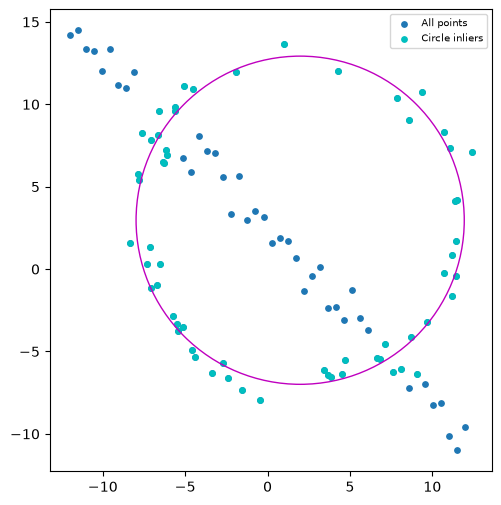

In [17]:
# Q2(d) - what happens if the circle is fitted first, on all points?
for sd in range(5):
    bad = ransac_circle(X, min_inliers=1, rng=np.random.default_rng(sd))
    c_, r_ = bad['refit']
    print(f"seed {sd}: inliers {bad['count']}, centre {np.round(c_, 1)}, radius {r_:.1f}")

bad = ransac_circle(X, min_inliers=1, rng=np.random.default_rng(1))
fig, ax = plt.subplots(figsize=(6, 6))
ax.scatter(*X.T, s=15, label='All points'); ax.scatter(*X[bad['inl']].T, c='c', s=15, label='Circle inliers')
ax.add_patch(plt.Circle(*bad['refit'], color='m', fill=False))
ax.set_aspect('equal'); ax.legend(fontsize=7); plt.show()

In [19]:
# Q2(d) - how many circle-first inliers are really line points, and can the line still be found afterwards?
bad = ransac_circle(X, min_inliers=1, rng=np.random.default_rng(1))
print("Inliers that are true circle points:", bad['inl'][:50].sum(), "of 50")
print("Inliers that are line points:", bad['inl'][50:].sum(), "of 50")
rest = X[~bad['inl']]
line2 = ransac_line(rest, min_inliers=1)
print("Points left:", len(rest), " line inliers:", line2['count'], " (a, b, d) =", np.round(line2['refit'], 3))
print("Would pass the min consensus of 35:", line2['count'] >= 35)

Inliers that are true circle points: 50 of 50
Inliers that are line points: 10 of 50
Points left: 40  line inliers: 40  (a, b, d) = [-0.724 -0.69  -1.649]
Would pass the min consensus of 35: True


### Q2(d): Fitting the circle first
The circle was fitted first, on all 100 points, with five different random seeds. In every run RANSAC
found the true circle: the inlier count was 59 or 60, the center was within about 0.3 of (2, 3) and the
radius was between 9.8 and 10.0. The result is stable across seeds.

This was not guaranteed. RANSAC keeps whichever model has the most inliers, and a circle with a very
large radius is almost a straight line, so it could have absorbed the line points. Here it did not,
because the true circle collects about 50 points while a near-straight circle through the noisy line
can collect fewer (an error threshold of 1.5 keeps only about 87 percent of the line points).

The circle's inlier count (59 to 60) is larger than the 50 true circle points, so about 10 line
points near the two crossings were counted as circle inliers. They are removed before the line is
fitted, leaving 40 points and a line with 40 inliers. Those points also pull the circle estimate
slightly (for example center (2.0, 2.9) and radius 9.8 in some seeds), which is a likely cause but was
not tested separately.

Fitting the line first is the safer order in general, since a line cannot imitate a circle but a large
circle can imitate a line. On this data both orders work, and the difference is only a small loss of
points near the crossings.

# Question 3: Homography Overlay

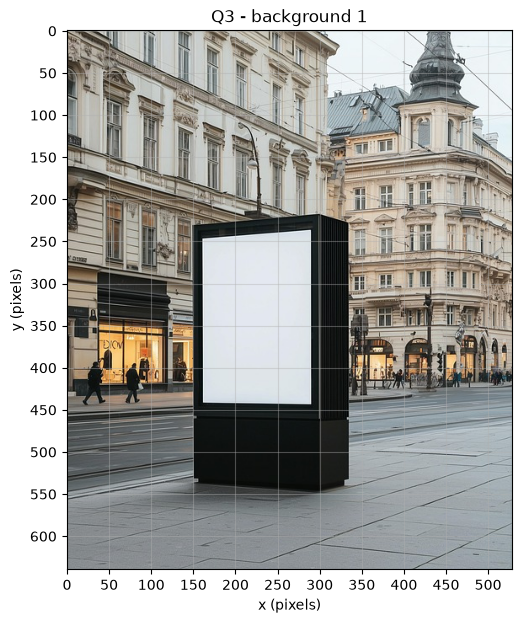

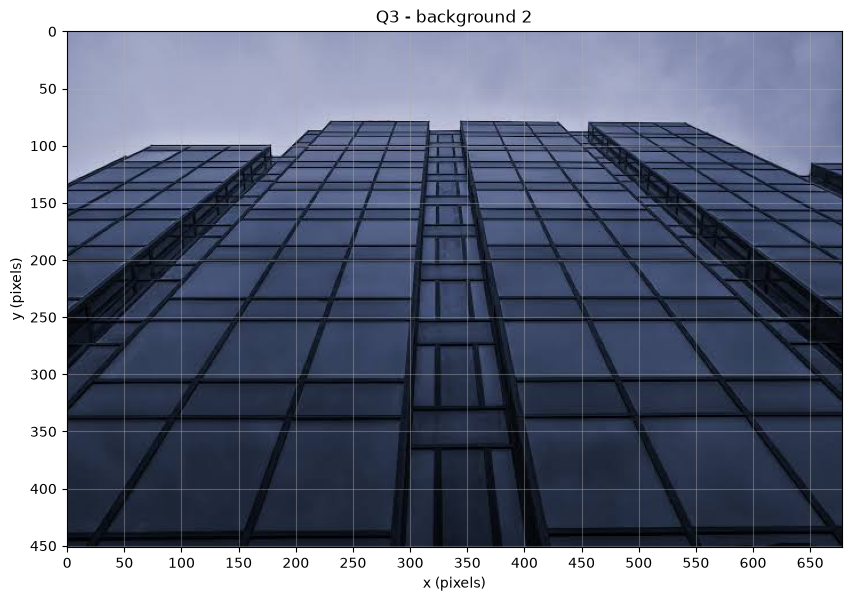

In [25]:
# Helper function to show an image with a pixel grid, so the four corner coordinates can be read off
def show_grid(img, title, step=50):
    plt.figure(figsize=(10, 7)); plt.imshow(cv.cvtColor(img, cv.COLOR_BGR2RGB))
    plt.xticks(range(0, img.shape[1], step)); plt.yticks(range(0, img.shape[0], step))
    plt.grid(alpha=0.4); plt.title(title); plt.xlabel('x (pixels)'); plt.ylabel('y (pixels)'); plt.show()

# Homography from the poster's 4 corners to the 4 clicked corners, then warp and blend
def overlay(bg, poster, corners, alpha=1.0):
    h, w = poster.shape[:2]
    src = np.float32([[0, 0], [w, 0], [w, h], [0, h]])      # poster corners: TL, TR, BR, BL
    dst = np.float32(corners)                               # surface corners in the same order
    H = cv.getPerspectiveTransform(src, dst)                # 3x3 matrix, 8 degrees of freedom
    size = (bg.shape[1], bg.shape[0])
    warped = cv.warpPerspective(poster, H, size)
    mask = cv.warpPerspective(np.full((h, w), 255, np.uint8), H, size) > 0   # where the poster landed
    out = bg.copy()
    out[mask] = ((1 - alpha) * bg[mask] + alpha * warped[mask]).astype(np.uint8)
    return H, out

poster = cv.imread('../images/poster.jpg')
bg1 = cv.imread('../images/bg_1.jpg')
bg2 = cv.imread('../images/bg_2.jpg')
assert poster is not None and bg1 is not None and bg2 is not None, "check the filenames in images/"
show_grid(bg1, 'Q3 - background 1')
show_grid(bg2, 'Q3 - background 2')

H1 =
 [[ 2.430e-01  1.600e-03  1.610e+02]
 [-5.710e-02  2.865e-01  2.470e+02]
 [-1.000e-04  0.000e+00  1.000e+00]]
H2 =
 [[ 2.547e-01 -2.418e-01  1.990e+02]
 [ 9.000e-04  1.610e-02  1.140e+02]
 [ 0.000e+00 -7.000e-04  1.000e+00]]


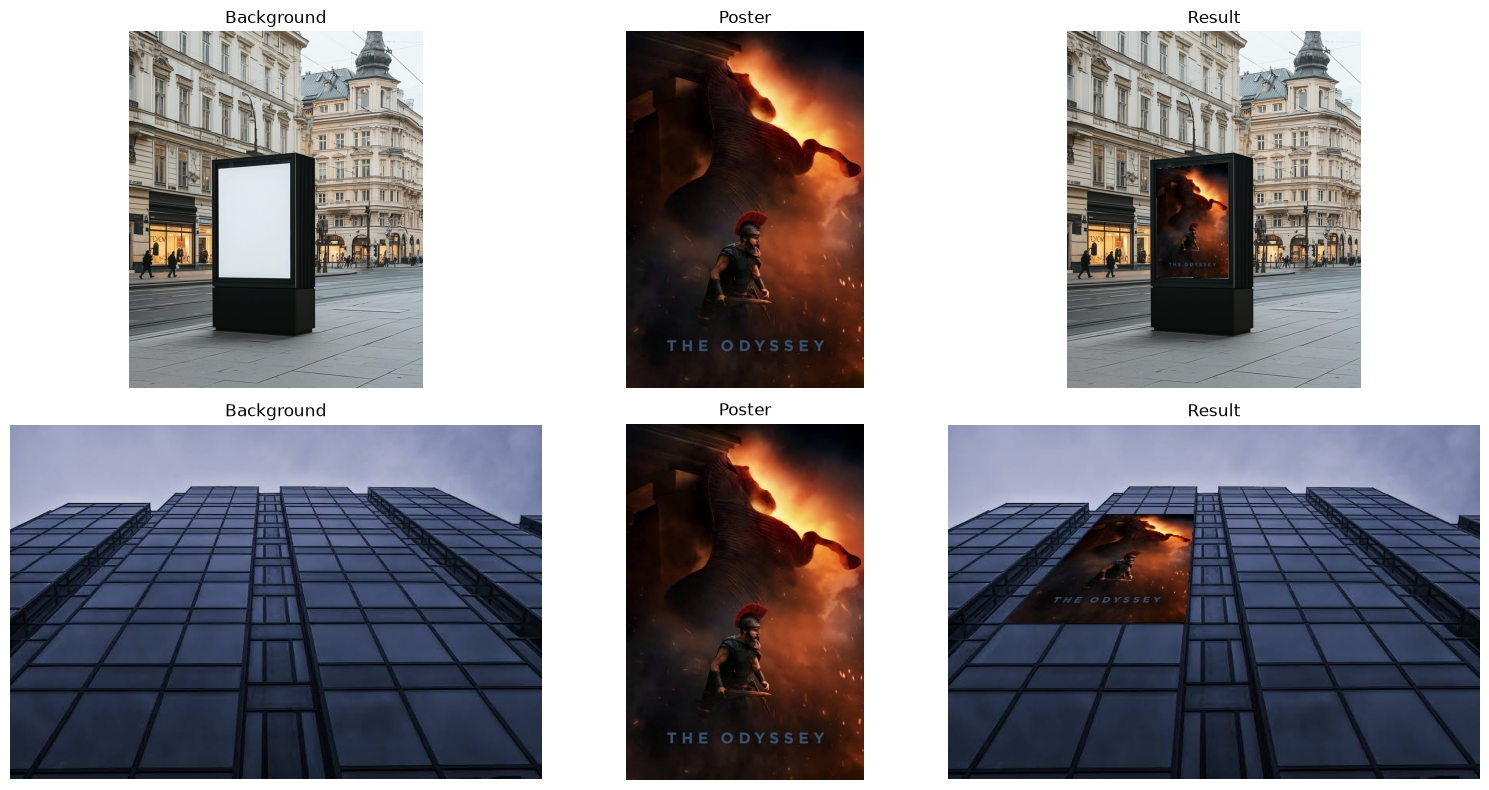

In [28]:
corners1 = [(161, 247), (289, 236), (290, 443), (162, 441)]
corners2 = [(199, 114), (313, 114), (302, 252), (71, 253)]

H1, out1 = overlay(bg1, poster, corners1)
H2, out2 = overlay(bg2, poster, corners2)
print("H1 =\n", np.round(H1, 4)); print("H2 =\n", np.round(H2, 4))

fig, ax = plt.subplots(2, 3, figsize=(15, 8))
for row, (bg, out) in enumerate([(bg1, out1), (bg2, out2)]):
    for a, im_, t in zip(ax[row], [bg, poster, out], ['Background', 'Poster', 'Result']):
        a.imshow(cv.cvtColor(im_, cv.COLOR_BGR2RGB)); a.set_title(t); a.axis('off')
plt.tight_layout(); plt.show()